# Full-throttle speed loss in 2026 F1 qualifying: season run

Runs the Japan-validated pipeline (`flatout.run_session`) on the main Qualifying session of every 2026 event held so far (conventional and sprint weekends; Sprint Qualifying is not used). Each session's tables go to `data/season/`; the QC summary has one row per session. Validation 1 needs each circuit's official length and is replaced here by a check that needs none: per push lap, car-data distance vs X/Y distance. OpenF1 brake values come from `openf1_session_key`; without a key, brake is taken at face value and logged. Sessions are tagged pre/post-Miami by Qualifying date relative to the Miami GP Qualifying.

**Calendar note.** The 2026 Bahrain and Saudi Arabian GPs were cancelled (OpenF1 `is_cancelled` for Sakhir and Jeddah); the Bahrain GP was rescheduled to Sepang, Malaysia (OpenF1 session 11730, location "Kuala Lumpur"), which FastF1 correctly lists as "Bahrain Grand Prix".

In [1]:
import re
import time
from pathlib import Path

import fastf1
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from flatout import (FIG, FULL_W, HALF_W, PU_COLORS, TAPER_ONSET_KMH, caption, distance_agreement, openf1_session_key, run_session,
                     to_seconds, load_quali, lap_geometry)

YEAR = 2026
DIST_FLAG_PCT = 3  # push laps whose car-data and X/Y distances differ by more than this are flagged
MIN_CLEAN_DRIVERS = 10  # reporting rule: a straight is reported for a session only with >= 10 clean drivers
OUT = Path("data/season")
OUT.mkdir(parents=True, exist_ok=True)

schedule = fastf1.get_event_schedule(YEAR, include_testing=False)
events = schedule[schedule.EventFormat.isin(["conventional", "sprint_qualifying"])].copy()  # all have a main "Qualifying"
events["QualiDateUtc"] = [next(r[f"Session{i}DateUtc"] for i in range(1, 6) if r[f"Session{i}"] == "Qualifying")
                          for _, r in events.iterrows()]
miami_q = events.loc[events.EventName.str.contains("Miami"), "QualiDateUtc"].iloc[0]  # rule changes apply from Miami onward
events["Period"] = np.where(events.QualiDateUtc < miami_q, "pre_miami", "post_miami")
now = pd.Timestamp.now(tz="UTC").tz_localize(None)
events = events[events.QualiDateUtc < now]
print(f"Miami GP qualifying (UTC): {miami_q}; now (UTC): {now:%Y-%m-%d %H:%M}; sessions held so far: {len(events)}\n")
print(events[["RoundNumber", "EventName", "Location", "QualiDateUtc", "Period"]].to_string(index=False))

req         WARNING 	DEFAULT CACHE ENABLED! (56.0 KB) C:\Users\User\AppData\Local\Temp\fastf1


Miami GP qualifying (UTC): 2026-05-02 20:00:00; now (UTC): 2026-10-16 15:14; sessions held so far: 17

 RoundNumber             EventName          Location        QualiDateUtc     Period
           1 Australian Grand Prix         Melbourne 2026-03-07 05:00:00  pre_miami
           2    Chinese Grand Prix          Shanghai 2026-03-14 07:00:00  pre_miami
           3   Japanese Grand Prix            Suzuka 2026-03-28 06:00:00  pre_miami
           4      Miami Grand Prix     Miami Gardens 2026-05-02 20:00:00 post_miami
           5   Canadian Grand Prix          Montréal 2026-05-23 20:00:00 post_miami
           6     Monaco Grand Prix       Monte Carlo 2026-06-06 14:00:00 post_miami
           7  Barcelona Grand Prix         Barcelona 2026-06-13 14:00:00 post_miami
           8   Austrian Grand Prix         Spielberg 2026-06-27 14:00:00 post_miami
           9    British Grand Prix       Silverstone 2026-07-04 15:00:00 post_miami
          10    Belgian Grand Prix Spa-Francorchamps 2026

## Run (one session at a time; a failure is logged and the loop continues)

In [2]:
rows = []
t_start = time.perf_counter()
for ev in events.itertuples():
    row = dict(Round=ev.RoundNumber, Event=ev.EventName, Period=ev.Period)
    t0 = time.perf_counter()
    try:
        tables, qc = run_session(YEAR, ev.RoundNumber, openf1_session=openf1_session_key(YEAR, ev.RoundNumber))
        dist = distance_agreement(tables["push"])
        stem = OUT / f"{ev.RoundNumber:02d}_{re.sub(r'[^A-Za-z0-9]+', '_', ev.Location).strip('_').lower()}"
        to_seconds(tables["sectors"]).to_csv(f"{stem}_sectors.csv", index=False)
        to_seconds(tables["segments"]).to_csv(f"{stem}_segments.csv", index=False)
        tables["exclusions"].to_csv(f"{stem}_exclusions.csv", index=False)
        dist.to_csv(f"{stem}_distance_qc.csv", index=False)
        cov = tables["coverage"]
        part = lambda k: cov.loc[k].to_dict() if k in cov.index.get_level_values(0) else {}
        row.update(Status="ok", **qc, Exclusions=len(tables["exclusions"]),
                   CleanPerStraight=part("straight"), CleanPerSector=part("sector"),
                   DistDiff_median_pct=dist.Diff_pct.abs().median(), DistDiff_max_pct=dist.Diff_pct.abs().max(),
                   LapsOver3pct=int((dist.Diff_pct.abs() > DIST_FLAG_PCT).sum()))
    except Exception as e:
        row.update(Status=f"error: {type(e).__name__}: {e}")
    row["Runtime_s"] = time.perf_counter() - t0
    rows.append(row)
    print(f"round {ev.RoundNumber:2d} {ev.EventName:<26} {row['Status'][:60]:<60} {row['Runtime_s']:6.0f} s", flush=True)
season_qc = pd.DataFrame(rows)
season_qc.to_csv(OUT / "qc_summary.csv", index=False)
print(f"\nTotal runtime: {(time.perf_counter() - t_start) / 60:.1f} min")

core        WARNING 	No lap data for driver 18


core        WARNING 	No lap data for driver 55


core        WARNING 	Failed to perform lap accuracy check - all laps marked as inaccurate (driver 18)


core        WARNING 	Failed to perform lap accuracy check - all laps marked as inaccurate (driver 55)


round  1 Australian Grand Prix      ok                                                               20 s


...

round 15 Azerbaijan Grand Prix      ok                                                               20 s


data        WARNING 	Failed to load circuit info


round 16 Bahrain Grand Prix         ok                                                               12 s


round 17 Singapore Grand Prix       ok                                                               19 s



Total runtime: 5.0 min


## QC summary (one row per session)

In [3]:
ok = season_qc.Status.eq("ok")
season_qc["Reportable"] = [sorted(k for k, n in d.items() if n >= MIN_CLEAN_DRIVERS) if isinstance(d, dict) else [] for d in season_qc.CleanPerStraight]
season_qc["NReportable"] = season_qc.Reportable.str.len().where(ok)
season_qc.to_csv(OUT / "qc_summary.csv", index=False)
cols = ["Round", "Event", "Period", "Status", "brake_source", "circuit_info", "push_laps", "push_lap_frozen_pct_mean",
        "DistDiff_median_pct", "DistDiff_max_pct", "LapsOver3pct", "CleanPerStraight", "NReportable", "Reportable", "Exclusions", "Runtime_s"]
pd.set_option("display.max_colwidth", 90)
season_qc.reindex(columns=cols).rename(columns={"push_lap_frozen_pct_mean": "FreezeShare_pct"}).round(1)

,Round,Event,Period,Status,brake_source,circuit_info,push_laps,FreezeShare_pct,DistDiff_median_pct,DistDiff_max_pct,LapsOver3pct,CleanPerStraight,NReportable,Reportable,Exclusions,Runtime_s
0,1,Australian Grand Prix,pre_miami,ok,OpenF1,ok,102,0.0,0.4,3.3,1,"{'T1': 2, 'T11': 18, 'T3': 5, 'T6': 7, 'T9': 19}",2,"[T11, T9]",248,19.9
1,2,Chinese Grand Prix,pre_miami,ok,OpenF1,ok,102,10.3,1.2,55.5,22,"{'T1': 18, 'T14': 21, 'T6': 1, 'T8': 19}",3,"[T1, T14, T8]",469,16.1
2,3,Japanese Grand Prix,pre_miami,ok,OpenF1,ok,108,10.6,0.5,39.8,10,"{'T1': 19, 'T13': 22, 'T16': 21}",3,"[T1, T13, T16]",580,18.1
3,4,Miami Grand Prix,post_miami,ok,OpenF1,ok,99,0.2,0.4,11.5,2,"{'T1': 16, 'T11': 22, 'T17': 22, 'T4': 6, 'T5': 4}",3,"[T1, T11, T17]",159,17.1
4,5,Canadian Grand Prix,post_miami,ok,OpenF1,ok,120,0.1,0.3,3.4,1,"{'T1': 14, 'T13': 22, 'T8': 14}",3,"[T1, T13, T8]",328,18.2
5,6,Monaco Grand Prix,post_miami,ok,OpenF1,ok,132,0.0,0.3,2.0,0,{'T10': 11},1,[T10],403,19.5
6,7,Barcelona Grand Prix,post_miami,ok,OpenF1,ok,74,0.1,0.3,1.4,0,{'T1': 22},1,[T1],155,15.3
7,8,Austrian Grand Prix,post_miami,ok,OpenF1,ok,91,0.2,0.2,3.2,1,"{'T1': 22, 'T3': 22, 'T4': 22, 'T9': 22}",4,"[T1, T3, T4, T9]",97,16.0
8,9,British Grand Prix,post_miami,ok,OpenF1,ok,92,0.0,0.2,0.9,0,"{'T1': 22, 'T10': 1, 'T11': 3, 'T12': 22, 'T13': 1, 'T15': 22, 'T6': 22, 'T9': 21}",5,"[T1, T12, T15, T6, T9]",180,19.0
9,10,Belgian Grand Prix,post_miami,ok,OpenF1,ok,87,0.2,0.1,0.8,0,"{'T12': 22, 'T18': 22, 'T5': 22}",3,"[T12, T18, T5]",188,20.2


## Coverage per period (sessions that ran)

Freeze share and clean-driver coverage, pre vs post Miami. Straight coverage counts drivers with a clean segment per labelled straight (main straight included); a straight is reportable with >= `MIN_CLEAN_DRIVERS` clean drivers.

In [4]:
done = season_qc[ok]
straight_n = lambda s: [n for d in s for n in d.values()]
by_period = done.groupby("Period", sort=False).agg(
    Sessions=("Round", "size"), PushLaps=("push_laps", "sum"),
    FreezeShare_mean_pct=("push_lap_frozen_pct_mean", "mean"), FreezeShare_max_pct=("push_lap_frozen_pct_mean", "max"),
    Straights=("CleanPerStraight", lambda s: len(straight_n(s))),
    ReportableStraights=("NReportable", "sum"),
    CleanDriversPerStraight_median=("CleanPerStraight", lambda s: np.median(straight_n(s))),
    CleanDriversPerSector_median=("CleanPerSector", lambda s: np.median(straight_n(s))),
    SessionsWithoutCircuitInfo=("circuit_info", lambda s: int((s != "ok").sum())),
)
by_period.round(1)

,Sessions,PushLaps,FreezeShare_mean_pct,FreezeShare_max_pct,Straights,ReportableStraights,CleanDriversPerStraight_median,CleanDriversPerSector_median,SessionsWithoutCircuitInfo
Period,,,,,,,,,
pre_miami,3,312,7.0,10.6,12,8,18.5,19.0,0
post_miami,14,1371,0.2,1.4,41,33,22.0,22.0,2


## Results (descriptive)

Descriptive only, no models (project scope). Only reportable straights are used: >= `MIN_CLEAN_DRIVERS` clean drivers in that session, where a straight is one labelled straight (or the main straight) in one session. **Centering:** each driver's clip_delta and decel_rate minus that straight's mean. This removes circuit and straight effects, including gradient, before pooling across the season. One or two cars per team, one lap per driver and straight.

In [5]:
seg = pd.concat([pd.read_csv(next(OUT.glob(f"{r.Round:02d}_*_segments.csv"))).assign(Round=r.Round, Event=r.Event, Period=r.Period)
                 for r in season_qc[ok].itertuples()], ignore_index=True)
seg["Straight"] = (seg.Round.map("{:02d}".format) + " " + seg.Event.str.replace(" Grand Prix", "") + " "
                   + np.where(seg.CrossesTimingLine, "main", seg.Label))
rep = seg[seg.groupby("Straight").Driver.transform("nunique") >= MIN_CLEAN_DRIVERS].copy()
for m in ["clip_delta", "decel_rate"]:
    rep[f"{m}_c"] = rep[m] - rep.groupby("Straight")[m].transform("mean")
BELOW, ABOVE = f"median peak < {TAPER_ONSET_KMH:.0f} km/h (full 350 kW)", f"median peak >= {TAPER_ONSET_KMH:.0f} km/h (taper)"
rep["Regime"] = np.where(rep.groupby("Straight").peak_speed.transform("median") < TAPER_ONSET_KMH, BELOW, ABOVE)
PUS = list(PU_COLORS)


def pu_summary(d, col):
    """Per PU: n driver-straights, median and IQR of `col`."""
    g = d.dropna(subset=[col]).groupby("PU")[col]
    return (pd.DataFrame({"n": g.size(), "median": g.median(), "q25": g.quantile(.25), "q75": g.quantile(.75)})
            .assign(IQR=lambda x: x.q75 - x.q25).reindex(PUS))


summ_a = pd.concat({m: pu_summary(rep, f"{m}_c") for m in ["clip_delta", "decel_rate"]}, axis=1)
summ_a.round(1)

C:\Users\User\AppData\Local\Temp\ipykernel_31720\4033215551.py:1: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  seg = pd.concat([pd.read_csv(next(OUT.glob(f"{r.Round:02d}_*_segments.csv"))).assign(Round=r.Round, Event=r.Event, Period=r.Period)


clip_delta                       decel_rate                      
                       n median  q25  q75  IQR          n median  q25  q75  IQR
PU                                                                             
Mercedes             302   -0.9 -3.9  1.7  5.5        245   -0.5 -1.6  1.4  3.0
Ferrari              234   -0.3 -3.5  2.4  5.9        201   -0.2 -2.4  1.3  3.7
Red Bull Ford        151   -0.5 -4.3  1.8  6.1        133   -0.1 -1.7  1.7  3.4
Honda                 76    1.1 -0.5  5.2  5.7         69    0.3 -1.5  1.8  3.3
Audi                  79    0.6 -2.1  4.1  6.2         73    0.3 -1.3  1.4  2.7

In [6]:
_r = {m: summ_a[m]["median"] for m in ["clip_delta", "decel_rate"]}
caption("Table", "a", f"Centered speed loss by PU, pooled over {rep.Straight.nunique()} reportable straights in {rep.Round.nunique()} sessions "
        f"({len(rep)} driver-straights): n, median and IQR of clip_delta (km/h) and decel_rate (km/h per 100 m) minus the straight mean. "
        f"PU medians span {_r['clip_delta'].min():.1f} to {_r['clip_delta'].max():.1f} km/h ({_r['clip_delta'].idxmin()} to {_r['clip_delta'].idxmax()}) "
        f"for clip_delta and {_r['decel_rate'].min():.2f} to {_r['decel_rate'].max():.2f} km/h per 100 m for decel_rate. Descriptive; no model.")

*Table 1. Centered speed loss by PU, pooled over 41 reportable straights in 16 sessions (842 driver-straights): n, median and IQR of clip_delta (km/h) and decel_rate (km/h per 100 m) minus the straight mean. PU medians span -0.9 to 1.1 km/h (Mercedes to Honda) for clip_delta and -0.49 to 0.29 km/h per 100 m for decel_rate. Descriptive; no model.*

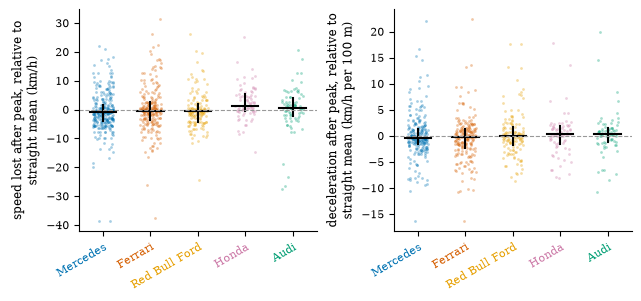

In [7]:
def centered_strip(d, path):
    """Centered clip_delta and decel_rate per PU: driver-straights (jittered), median (bar) and IQR (line)."""
    rng = np.random.default_rng(0)
    fig, axes = plt.subplots(1, 2, figsize=(FULL_W, 2.9), layout="constrained")
    for ax, (m, ylabel) in zip(axes, [("clip_delta_c", "speed lost after peak, relative to\nstraight mean (km/h)"),
                                      ("decel_rate_c", "deceleration after peak, relative to\nstraight mean (km/h per 100 m)")]):
        for i, pu in enumerate(PUS):
            v = d.loc[d.PU == pu, m].dropna()
            ax.scatter(i + rng.uniform(-0.22, 0.22, len(v)), v, s=4, alpha=0.35, color=PU_COLORS[pu], lw=0)
            q25, q50, q75 = v.quantile([.25, .5, .75])
            ax.plot([i, i], [q25, q75], color="black", lw=1.5)
            ax.plot([i - 0.28, i + 0.28], [q50, q50], color="black", lw=1.5)
        ax.axhline(0, color="0.6", lw=0.8, ls="--")
        ax.set_xticks(range(len(PUS)), PUS, rotation=30, ha="right", rotation_mode="anchor")
        for t, pu in zip(ax.get_xticklabels(), PUS):
            t.set_color(PU_COLORS[pu])
        ax.set_ylabel(ylabel)
    fig.savefig(FIG / path)
    plt.show()


centered_strip(rep, "fig_season_centered_by_pu.pdf")

In [8]:
caption("Figure", "a", f"Centered clip_delta (left) and decel_rate (right) per PU across {rep.Straight.nunique()} reportable straights: "
        "dots = driver-straights, black bar = median, black line = IQR; 0 = straight mean. Centering removes circuit and straight "
        "effects, including gradient. Descriptive; one or two cars per team.")

*Figure 1. Centered clip_delta (left) and decel_rate (right) per PU across 41 reportable straights: dots = driver-straights, black bar = median, black line = IQR; 0 = straight mean. Centering removes circuit and straight effects, including gradient. Descriptive; one or two cars per team.*

### Regulation regime

Straights split by their median peak speed relative to the C5.2.8 taper onset (`TAPER_ONSET_KMH`, where 1800 − 5v meets the 350 kW cap of C5.2.7): below it, the full 350 kW is allowed at the peak; above it, the allowed MGU-K power falls with speed.

In [9]:
summ_b = pd.concat({(reg, m): pu_summary(d, f"{m}_c") for reg, d in rep.groupby("Regime") for m in ["clip_delta", "decel_rate"]}, axis=1)
summ_b.round(1)

median peak < 290 km/h (full 350 kW)                                                         median peak >= 290 km/h (taper)                                                       
                                        clip_delta                       decel_rate                                             clip_delta                       decel_rate                      
                                                 n median  q25  q75  IQR          n median  q25  q75   IQR                               n median  q25  q75  IQR          n median  q25  q75  IQR
PU                                                                                                                                                                                               
Mercedes                                        27   -0.1 -2.3  5.7  8.0         24   -0.2 -5.8  4.5  10.3                             275   -0.9 -3.9  1.4  5.4        221   -0.5 -1.5  1.3  2.9
Ferrari                                         26   -0.4 -3.9  0.6  4.5         20   -0.3 -4.3  1.0   5.3                             208   -0.3 -3.4  2.5  5.9        181   -0.2 -2.3  1.3  3.6
Red Bull Ford                                   17   -0.4 -4.8 -0.1  4.7         10    2.3 -0.5  6.7   7.2                             134   -0.9 -3.8  2.2  6.0        123   -0.2 -1.8  1.5  3.3
Honda                                           10   -0.1 -4.2  0.2  4.4          7   -0.7 -2.7  7.5  10.3                              66    2.4 -0.5  5.8  6.3         62    0.3 -1.4  1.8  3.2
Audi                                             8    2.9  0.2  7.3  7.1          8   -0.1 -6.7  1.1   7.8                              71    0.5 -2.5  3.0  5.5         65    0.3 -1.1  1.4  2.5

In [10]:
_n = rep.groupby("Regime").Straight.nunique()
_m = {reg: summ_b[(reg, "clip_delta")]["median"] for reg in _n.index}
caption("Table", "b", "Centered speed loss by PU and regulation regime: " + "; ".join(
    f"{reg}: {_n[reg]} straights, {int(summ_b[(reg, 'clip_delta')]['n'].sum())} driver-straights, PU medians of centered clip_delta "
    f"{_m[reg].min():.1f} to {_m[reg].max():.1f} km/h" for reg in _n.index) + ". Descriptive; no model.")

*Table 2. Centered speed loss by PU and regulation regime: median peak < 290 km/h (full 350 kW): 5 straights, 88 driver-straights, PU medians of centered clip_delta -0.4 to 2.9 km/h; median peak >= 290 km/h (taper): 36 straights, 754 driver-straights, PU medians of centered clip_delta -0.9 to 2.4 km/h. Descriptive; no model.*

### Teammates vs power units (after Bopaiah & Samuel's STDD/SPDT)

How large are differences between teammates (same car, same straight) compared with differences between PUs, on centered clip_delta?

In [11]:
pairs = rep.groupby(["Straight", "Team"]).filter(lambda g: len(g) == 2)
stdd_abs = pairs.groupby(["Straight", "Team"]).clip_delta_c.agg(lambda x: abs(x.iloc[0] - x.iloc[1]))
team_med = rep.groupby(["PU", "Team"]).clip_delta_c.median()
spdt_rng = team_med.groupby("PU").agg(lambda x: x.max() - x.min() if len(x) > 1 else np.nan).dropna()
pu_med = rep.groupby("PU").clip_delta_c.median()
spread = pd.DataFrame({
    "n": [len(stdd_abs), len(spdt_rng), len(pu_med)],
    "median": [stdd_abs.median(), spdt_rng.median(), pu_med.median()],
    "spread": [stdd_abs.quantile(.75) - stdd_abs.quantile(.25), spdt_rng.max() - spdt_rng.min(), pu_med.max() - pu_med.min()],
    "spread measure": ["IQR", "max - min of ranges", "max - min of PU medians"],
}, index=["STDD: |teammate difference| per straight", "SPDT: range of team medians within a PU", "PU medians"])
spread.round(1)

,n,median,spread,spread measure
STDD: |teammate difference| per straight,408,2.0,3.0,IQR
SPDT: range of team medians within a PU,3,3.5,2.7,max - min of ranges
PU medians,5,-0.3,2.1,max - min of PU medians


In [12]:
caption("Table", "c", f"Teammates on the same straight differ by a median {stdd_abs.median():.1f} km/h in centered clip_delta "
        f"(IQR {stdd_abs.quantile(.25):.1f}–{stdd_abs.quantile(.75):.1f}, {len(stdd_abs)} pairs), while the {len(pu_med)} PU medians span "
        f"{pu_med.max() - pu_med.min():.1f} km/h and team medians within a PU span up to {spdt_rng.max():.1f} km/h. Descriptive.")

*Table 3. Teammates on the same straight differ by a median 2.0 km/h in centered clip_delta (IQR 1.0–4.0, 408 pairs), while the 5 PU medians span 2.1 km/h and team medians within a PU span up to 3.8 km/h. Descriptive.*

### Data quality across the season

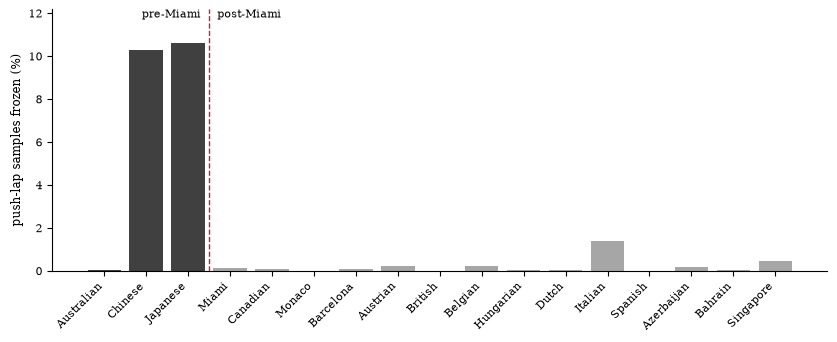

In [13]:
dq = season_qc[ok].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(range(len(dq)), dq.push_lap_frozen_pct_mean, color=np.where(dq.Period == "pre_miami", "0.25", "0.65"))
first_post = int((dq.Period == "post_miami").idxmax())
ax.axvline(first_post - 0.5, color="crimson", ls="--", lw=1)
top = dq.push_lap_frozen_pct_mean.max() * 1.15
ax.set_ylim(0, top)
ax.text(first_post - 0.6, top, "pre-Miami ", ha="right", va="top", fontsize=8)
ax.text(first_post - 0.4, top, " post-Miami", ha="left", va="top", fontsize=8)
ax.set_xticks(range(len(dq)), [e.replace(" Grand Prix", "") for e in dq.Event], rotation=45, ha="right", fontsize=8)
ax.set_ylabel("push-lap samples frozen (%)")
fig.savefig(FIG / "fig_season_freeze_share.pdf")
plt.show()

In [14]:
_p = dq.groupby("Period", sort=False).push_lap_frozen_pct_mean.mean()
caption("Figure", "dq", f"Share of push-lap car-data samples flagged as frozen, per session in date order: mean {_p['pre_miami']:.1f} % pre-Miami "
        f"vs {_p['post_miami']:.1f} % post-Miami; highest {dq.push_lap_frozen_pct_mean.max():.1f} % ({dq.loc[dq.push_lap_frozen_pct_mean.idxmax(), 'Event']}).")

*Figure 2. Share of push-lap car-data samples flagged as frozen, per session in date order: mean 7.0 % pre-Miami vs 0.2 % post-Miami; highest 10.6 % (Japanese Grand Prix).*

### Pre- vs post-Miami (descriptive)

In [15]:
by_p = rep.groupby("Period", sort=False).agg(Sessions=("Round", "nunique"), Straights=("Straight", "nunique"), DriverStraights=("Driver", "size"),
                                              clip_delta_median=("clip_delta", "median"), decel_rate_median=("decel_rate", "median"),
                                              peak_speed_median=("peak_speed", "median"))
by_p["FreezeShare_mean_pct"] = dq.groupby("Period").push_lap_frozen_pct_mean.mean()
by_p.round(1)

,Sessions,Straights,DriverStraights,clip_delta_median,decel_rate_median,peak_speed_median,FreezeShare_mean_pct
Period,,,,,,,
pre_miami,3,8,157,26.0,8.4,319.0,7.0
post_miami,13,33,685,9.0,6.0,313.0,0.2


In [16]:
_venues = {p: set(schedule.set_index("RoundNumber").loc[rep.loc[rep.Period == p, "Round"].unique(), "Location"]) for p in by_p.index}
_shared = set.intersection(*_venues.values()) if len(_venues) > 1 else set()
caption("Table", "e", "Reportable straights before and after the Miami rule changes (raw, uncentered values): "
        + "; ".join(f"{p}: {int(r.Sessions)} sessions, {int(r.Straights)} straights, median clip_delta {r.clip_delta_median:.1f} km/h, "
                    f"median peak {r.peak_speed_median:.0f} km/h" for p, r in by_p.iterrows())
        + f". Caveats: {'no circuit appears in both periods' if not _shared else 'circuits in both periods: ' + ', '.join(sorted(_shared))}, "
        f"so circuit and regulation effects are confounded; pre-Miami data quality was worse (mean freeze share "
        f"{by_p.loc['pre_miami', 'FreezeShare_mean_pct']:.1f} % vs {by_p.loc['post_miami', 'FreezeShare_mean_pct']:.1f} %).")

*Table 4. Reportable straights before and after the Miami rule changes (raw, uncentered values): pre_miami: 3 sessions, 8 straights, median clip_delta 26.0 km/h, median peak 319 km/h; post_miami: 13 sessions, 33 straights, median clip_delta 9.0 km/h, median peak 313 km/h. Caveats: no circuit appears in both periods, so circuit and regulation effects are confounded; pre-Miami data quality was worse (mean freeze share 7.0 % vs 0.2 %).*

### Peak speed and speed loss

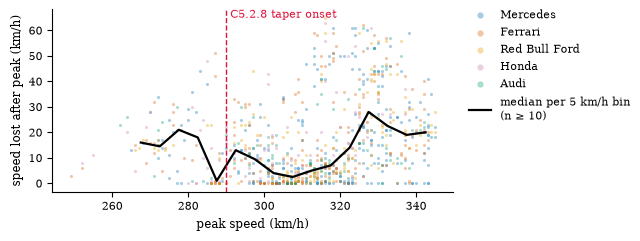

In [17]:
fig, ax = plt.subplots(figsize=(FULL_W, 2.3), layout="constrained")
for pu in PUS:
    d = rep[rep.PU == pu]
    ax.scatter(d.peak_speed, d.clip_delta, s=5, alpha=0.35, color=PU_COLORS[pu], lw=0, label=pu)
bins = np.arange(np.floor(rep.peak_speed.min() / 5) * 5, rep.peak_speed.max() + 5, 5)
g = rep.groupby(pd.cut(rep.peak_speed, bins), observed=True).clip_delta
MIN_BIN_N = 10  # bin medians are drawn only for bins with at least this many driver-straights
binned_all = pd.DataFrame({"mid": [i.mid for i in g.median().index], "median": g.median().to_numpy(), "n": g.size().to_numpy()})
binned = binned_all[binned_all.n >= MIN_BIN_N]
ax.plot(binned.mid, binned["median"], color="black", lw=1.6, label=f"median per 5 km/h bin\n(n ≥ {MIN_BIN_N})")
ax.axvline(TAPER_ONSET_KMH, color="crimson", ls="--", lw=1)
ax.text(TAPER_ONSET_KMH, ax.get_ylim()[1], " C5.2.8 taper onset", va="top", fontsize=8, color="crimson")
ax.set(xlabel="peak speed (km/h)", ylabel="speed lost after peak (km/h)")
fig.legend(frameon=False, markerscale=2, loc="outside right upper")  # inside the 6.3 in canvas
fig.savefig(FIG / "fig_season_peak_vs_clip.pdf")
plt.show()

In [18]:
_below, _above = rep[rep.peak_speed < TAPER_ONSET_KMH], rep[rep.peak_speed >= TAPER_ONSET_KMH]
_rho = _above[["peak_speed", "clip_delta"]].corr(method="spearman").iloc[0, 1]
_sparse = binned_all[binned_all.n < MIN_BIN_N]
caption("Figure", "scatter", f"Speed lost after peak (clip_delta) vs peak speed, one point per driver-straight on {rep.Straight.nunique()} reportable "
        f"straights, coloured by PU; black line = median per 5 km/h bin, drawn only for bins with >= {MIN_BIN_N} driver-straights "
        f"({len(_sparse)} sparser bins with {int(_sparse.n.sum())} points in total omitted from the line); dashed = C5.2.8 taper onset "
        f"({TAPER_ONSET_KMH:.0f} km/h). Median speed lost after peak {_below.clip_delta.median():.1f} km/h below the onset (n = {len(_below)}) vs "
        f"{_above.clip_delta.median():.1f} km/h above it (n = {len(_above)}); Spearman correlation of peak speed and speed lost after peak above the "
        f"onset: {_rho:.2f}. Above the onset, speed lost after peak "
        + ("increases with peak speed, consistent with the speed-dependent C5.2.8 limit" if _rho > 0 else "does not increase with peak speed")
        + "; straight length and circuit are confounded (raw values). Descriptive.")

*Figure 3. Speed lost after peak (clip_delta) vs peak speed, one point per driver-straight on 41 reportable straights, coloured by PU; black line = median per 5 km/h bin, drawn only for bins with >= 10 driver-straights (3 sparser bins with 8 points in total omitted from the line); dashed = C5.2.8 taper onset (290 km/h). Median speed lost after peak 13.0 km/h below the onset (n = 106) vs 11.0 km/h above it (n = 736); Spearman correlation of peak speed and speed lost after peak above the onset: 0.36. Above the onset, speed lost after peak increases with peak speed, consistent with the speed-dependent C5.2.8 limit; straight length and circuit are confounded (raw values). Descriptive.*

In [19]:
def corners_passed(d):
    """Corners from FastF1's corner list that a straight's segments pass through before the corner they end at: the modal
    `Via` of labelled straights; for the main straight, corners inside its median window around the timing line."""
    if not d.CrossesTimingLine.iloc[0]:
        return d.Via.fillna("").mode().iloc[0]
    ses = load_quali(2026, int(d.Round.iloc[0]))
    xyd, _, cpos = lap_geometry(ses.laps.pick_fastest(), ses.get_circuit_info().corners.set_index("Number"))
    a, b = d.start_m.median(), d.end_m.median()  # metres relative to the timing line
    return ",".join(f"T{n}" for n, x in cpos.items() if x > xyd[-1] + a or x < b)


_low = rep[rep.groupby("Straight").peak_speed.transform("median") < TAPER_ONSET_KMH]
_via = {s: corners_passed(d) for s, d in _low.groupby("Straight")}
_with = [s for s, v in _via.items() if v]
caption("Table", "below_onset", f"Straights with median peak speed below the {TAPER_ONSET_KMH:.0f} km/h onset: {len(_with)} of {len(_via)} pass "
        f"through at least one other corner within the full-throttle segment, i.e. a corner taken flat out ("
        + "; ".join(f"{s}: via {v}" for s, v in _via.items() if v) + "); "
        + ("; ".join(f"{s}: none" for s, v in _via.items() if not v) or "none without") + ".")

*Table 5. Straights with median peak speed below the 290 km/h onset: 4 of 5 pass through at least one other corner within the full-throttle segment, i.e. a corner taken flat out (02 Chinese T8: via T7; 06 Monaco T10: via T9; 10 Belgian T12: via T10,T11; 15 Azerbaijan T15: via T13,T14); 05 Canadian main: none.*

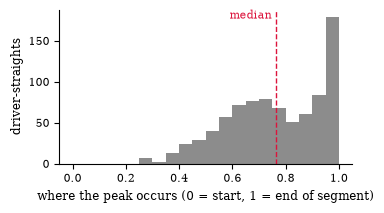

In [20]:
fig, ax = plt.subplots(figsize=(0.6 * FULL_W, 2.0))
ax.hist(rep.vmax_position, bins=np.linspace(0, 1, 21), color="0.55")
ax.axvline(rep.vmax_position.median(), color="crimson", ls="--", lw=1)
ax.text(rep.vmax_position.median(), ax.get_ylim()[1], "median ", color="crimson", va="top", ha="right", fontsize=8)
ax.set(xlabel="where the peak occurs (0 = start, 1 = end of segment)", ylabel="driver-straights")
fig.savefig(FIG / "fig_season_vmax_position.pdf")
plt.show()

In [21]:
caption("Figure", "vmax", f"Where on the straight the peak speed occurs (vmax_position), all {len(rep)} driver-straights on {rep.Straight.nunique()} "
        f"reportable straights: {(rep.vmax_position < 1).mean():.0%} peak before the segment end (vmax_position < 1); median "
        f"{rep.vmax_position.median():.2f} (dashed). The Race (\"Why key 2026 F1 rules fix will create another problem\", 20 Apr 2026) describes 2026 "
        "cars peaking earlier on a straight than earlier cars; that comparison across car generations cannot be tested with 2026 data alone. Descriptive.")

*Figure 4. Where on the straight the peak speed occurs (vmax_position), all 842 driver-straights on 41 reportable straights: 86% peak before the segment end (vmax_position < 1); median 0.76 (dashed). The Race ("Why key 2026 F1 rules fix will create another problem", 20 Apr 2026) describes 2026 cars peaking earlier on a straight than earlier cars; that comparison across car generations cannot be tested with 2026 data alone. Descriptive.*